# Which Exploited Vulnerabilities Become Ransomware Targets?

### A machine learning analysis of the CISA Known Exploited Vulnerabilities catalog

**Module:** Data Analysis and Machine Learning with Python

---

## Project objective

Two questions about vulnerabilities that are confirmed exploited in the wild:

1. **How quickly are disclosed vulnerabilities weaponised**, and can that speed be predicted from
   the vulnerability's own technical characteristics?
2. **Which exploited vulnerabilities get adopted into ransomware campaigns?**

The first question produces a negative result that is the most important finding in this notebook.
The second produces a working classifier.

## Dataset

This dataset was **constructed for this project** by joining two authoritative sources. It is not
a pre-packaged file downloaded from a repository.

| | |
|---|---|
| **Source A** | CISA Known Exploited Vulnerabilities (KEV) catalog |
| | US Cybersecurity and Infrastructure Security Agency |
| | `https://github.com/cisagov/kev-data` |
| **Source B** | MITRE CVE Program record list (CVE List V5) |
| | `https://github.com/CVEProject/cvelistV5` |
| **Join** | Every CVE in the KEV catalog matched to its authoritative CVE Program record |
| **Records** | 1,694 confirmed exploited vulnerabilities |
| **Variables** | 39 (numerical, categorical, temporal and text) |
| **Coverage** | CVEs published 2002 to 2026, KEV listings 2021-11-03 to 2026-09-02 |
| **Build script** | `build_dataset.py`, included with this submission |

From each CVE Program record the build script extracted the CVSS v3.1 base score and its eight
vector components, CISA's SSVC decision points (Exploitation, Automatable, Technical Impact),
CWE weakness identifiers, publication dates, reference counts and affected-product counts.

## Why this catalog

CISA's KEV catalog is a list of vulnerabilities with confirmed evidence of active exploitation.
US federal agencies are legally required to remediate everything on it within a set deadline.
That makes it a ground-truth label for "actually dangerous", as opposed to CVSS, which is an
analyst's assessment of how bad a vulnerability could be in principle.

## 1. Setup and data loading

In [1]:
import warnings
import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)
DATADIR = Path("data")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["font.size"] = 10
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 50)

RESULTS = {}
KEV_LAUNCH = pd.Timestamp("2021-11-03")   # first day of the KEV catalog
print("Environment ready.")

Environment ready.


In [2]:
df_raw = pd.read_csv(DATADIR / "kev_cve_enriched_raw.csv")
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
df_raw.head(3)

Rows: 1,694   Columns: 39


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes,datePublished,dateReserved,assignerShortName,cveState,description,desc_word_count,reference_count,has_exploit_reference,has_patch_reference,cwe_list,cwe_count,cwe_primary,ssvc_exploitation,ssvc_automatable,ssvc_technical_impact,affected_entry_count,cvss_base_score,cvss_severity,attack_vector,attack_complexity,privileges_required,user_interaction,scope_changed,confidentiality_impact,integrity_impact,availability_impact,cvss_vector
0,CVE-2026-59822,BerriAI,LiteLLM,BerriAI LiteLLM Improper Authentication Vulner...,2026-09-02,BerriAI LiteLLM contains an improper authentic...,Apply mitigations in accordance with vendor in...,2026-09-16,Unknown,No,https://github.com/BerriAI/litellm/security/ad...,"CWE-287, CWE-306",2026-07-08,2026-07-07,GitHub_M,PUBLISHED,LiteLLM is a proxy server (AI Gateway) to call...,70,6,0,0,CWE-287;CWE-306,2,CWE-287,active,yes,partial,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CVE-2026-48710,Kludex,Starlette,Kludex Starlette HTTP Request/Response Smuggli...,2026-09-02,Kludex Starlette contains a HTTP request/respo...,Apply mitigations in accordance with vendor in...,2026-09-16,Unknown,No,This vulnerability affects an open-source comp...,CWE-444,2026-05-26,2026-05-22,GitHub_M,PUBLISHED,Starlette is a lightweight ASGI framework/tool...,116,28,0,1,CWE-1289;CWE-444,2,CWE-1289,active,yes,partial,1,6.5,MEDIUM,NETWORK,LOW,NONE,NONE,UNCHANGED,LOW,LOW,NONE,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:L/I:L/A:N
2,CVE-2026-49869,Kestra,Kestra OSS,Kestra OSS OS Command Injection Vulnerability,2026-09-02,Kestra OSS contains an OS command injection vu...,Apply mitigations in accordance with vendor in...,2026-09-05,Unknown,Yes,This vulnerability affects an open-source comp...,"CWE-78, CWE-184, CWE-287, CWE-918",2026-06-26,2026-06-01,GitHub_M,PUBLISHED,"Kestra is an open-source, event-driven orchest...",102,2,0,0,CWE-184;CWE-287;CWE-78;CWE-918,4,CWE-184,active,yes,total,1,10.0,CRITICAL,NETWORK,LOW,NONE,NONE,CHANGED,HIGH,HIGH,HIGH,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:C/C:H/I:H/A:H


In [3]:
df_raw.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 1694 entries, 0 to 1693
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   cveID                       1694 non-null   str    
 1   vendorProject               1694 non-null   str    
 2   product                     1694 non-null   str    
 3   vulnerabilityName           1694 non-null   str    
 4   dateAdded                   1694 non-null   str    
 5   shortDescription            1694 non-null   str    
 6   requiredAction              1694 non-null   str    
 7   dueDate                     1694 non-null   str    
 8   knownRansomwareCampaignUse  1694 non-null   str    
 9   forensicTriage              1694 non-null   str    
 10  notes                       1694 non-null   str    
 11  cwes                        1519 non-null   str    
 12  datePublished               1694 non-null   str    
 13  dateReserved                1694 non-null   

In [4]:
n_num = df_raw.select_dtypes(include=np.number).shape[1]
n_cat = df_raw.select_dtypes(exclude=np.number).shape[1]
print(f"Numerical columns   : {n_num}")
print(f"Non-numerical       : {n_cat}")
print(f"Unique vendors      : {df_raw['vendorProject'].nunique()}")
print(f"Unique products     : {df_raw['product'].nunique()}")
print(f"Unique CWE types    : {df_raw['cwe_primary'].nunique()}")

RESULTS["n_rows_raw"] = int(df_raw.shape[0])
RESULTS["n_cols_raw"] = int(df_raw.shape[1])
RESULTS["n_vendors"] = int(df_raw["vendorProject"].nunique())
RESULTS["n_cwe"] = int(df_raw["cwe_primary"].nunique())

Numerical columns   : 7
Non-numerical       : 32
Unique vendors      : 283
Unique products     : 689
Unique CWE types    : 164


## 2. Data cleaning

Unlike many teaching datasets this one has genuine missing data, because it was assembled from
live sources rather than curated. Roughly one record in five has no CVSS vector. Cleaning
proceeds through column naming, type conversion, duplicates, missing values, category
cardinality and outliers.

### 2.1 Column names

The KEV catalog uses camelCase, the fields added by the build script use snake_case. Mixing the
two invites lookup errors, so everything is converted to snake_case.

In [5]:
import re

def to_snake(name: str) -> str:
    # insert an underscore at lower-to-upper boundaries, then normalise
    s = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", name)
    s = re.sub(r"[^0-9a-zA-Z]+", "_", s).lower()
    return re.sub(r"_+", "_", s).strip("_")

df = df_raw.copy()
df.columns = [to_snake(c) for c in df.columns]
print("Renamed columns:")
for a, b in zip(df_raw.columns, df.columns):
    if a != b:
        print(f"  {a:<30} -> {b}")

Renamed columns:
  cveID                          -> cve_id
  vendorProject                  -> vendor_project
  vulnerabilityName              -> vulnerability_name
  dateAdded                      -> date_added
  shortDescription               -> short_description
  requiredAction                 -> required_action
  dueDate                        -> due_date
  knownRansomwareCampaignUse     -> known_ransomware_campaign_use
  forensicTriage                 -> forensic_triage
  datePublished                  -> date_published
  dateReserved                   -> date_reserved
  assignerShortName              -> assigner_short_name
  cveState                       -> cve_state


### 2.2 Dates and the target variable

Three dates matter: when the CVE record was published, when CISA added it to KEV, and the
remediation deadline CISA set. The gap between the first two is the exploitation lag.

In [6]:
df["date_added"] = pd.to_datetime(df["date_added"])
df["due_date"] = pd.to_datetime(df["due_date"])
df["date_published"] = pd.to_datetime(df["date_published"], format="mixed", utc=True).dt.tz_localize(None)
df["date_reserved"] = pd.to_datetime(df["date_reserved"], format="mixed", utc=True, errors="coerce").dt.tz_localize(None)

df["exploitation_lag_days"] = (df["date_added"] - df["date_published"]).dt.days
df["remediation_window_days"] = (df["due_date"] - df["date_added"]).dt.days
df["cve_year"] = df["cve_id"].str.split("-").str[1].astype(int)
df["kev_year"] = df["date_added"].dt.year

print(f"CVE publication dates : {df['date_published'].min().date()} to {df['date_published'].max().date()}")
print(f"KEV listing dates     : {df['date_added'].min().date()} to {df['date_added'].max().date()}")
print()
print("Exploitation lag (days from CVE publication to KEV listing):")
print(df["exploitation_lag_days"].describe().round(1).to_string())

CVE publication dates : 2003-04-02 to 2026-09-01
KEV listing dates     : 2021-11-03 to 2026-09-02

Exploitation lag (days from CVE publication to KEV listing):
count    1694.0
mean      876.3
std      1243.2
min      -290.0
25%         9.0
50%       262.0
75%      1393.0
max      6910.0


A negative lag means CISA listed the vulnerability as actively exploited *before* its CVE record
was published. These are zero-days: exploitation was observed in the wild before public
disclosure. They are valid observations, not data errors, and are kept.

In [7]:
zero_day = (df["exploitation_lag_days"] <= 0).sum()
print(f"Listed on or before publication date (zero-day) : {zero_day} ({zero_day/len(df):.1%})")
print(f"Listed within 7 days                            : {(df['exploitation_lag_days'] <= 7).sum()}")
print(f"Listed within 30 days                           : {(df['exploitation_lag_days'] <= 30).sum()}")
print(f"Listed more than a year later                   : {(df['exploitation_lag_days'] > 365).sum()}")
print(f"\nMost extreme negative lag: {df['exploitation_lag_days'].min()} days")
RESULTS["zero_day_count"] = int(zero_day)

Listed on or before publication date (zero-day) : 212 (12.5%)
Listed within 7 days                            : 402
Listed within 30 days                           : 525
Listed more than a year later                   : 782

Most extreme negative lag: -290 days


### 2.3 Duplicates

In [8]:
print(f"Fully duplicated rows : {df.duplicated().sum()}")
print(f"Duplicated CVE IDs    : {df['cve_id'].duplicated().sum()}")
print(f"Distinct CVE IDs      : {df['cve_id'].nunique():,} of {len(df):,} rows")

Fully duplicated rows : 0
Duplicated CVE IDs    : 0
Distinct CVE IDs      : 1,694 of 1,694 rows


### 2.4 Missing values

This is where most of the cleaning effort goes. The missingness is not random, and treating it
as random would throw away information.

In [9]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
pd.DataFrame({"missing": miss, "percent": (miss / len(df) * 100).round(1)})

,missing,percent
attack_vector,317,18.7
scope_changed,317,18.7
availability_impact,317,18.7
integrity_impact,317,18.7
confidentiality_impact,317,18.7
privileges_required,317,18.7
user_interaction,317,18.7
attack_complexity,317,18.7
cwe_list,216,12.8
cwe_primary,216,12.8


In [10]:
# The eight CVSS vector components are missing together, as a block.
CVSS_COMPONENTS = ["attack_vector", "attack_complexity", "privileges_required", "user_interaction",
                   "scope_changed", "confidentiality_impact", "integrity_impact", "availability_impact"]

block = df[CVSS_COMPONENTS].isna().sum(axis=1)
print("Number of CVSS components missing per row:")
print(block.value_counts().sort_index().to_string())
print("\nAll eight are absent together, so this is one missing record rather than eight gaps.")

Number of CVSS components missing per row:


0    1377
8     317

All eight are absent together, so this is one missing record rather than eight gaps.


In [11]:
# Is the missingness random? Compare CVE age for rows with and without a CVSS vector.
df["has_cvss_vector"] = df["attack_vector"].notna().astype(int)
comp = df.groupby("has_cvss_vector").agg(
    n=("cve_id", "size"),
    median_cve_year=("cve_year", "median"),
    mean_cve_year=("cve_year", "mean"),
    pct_ransomware=("known_ransomware_campaign_use", lambda s: (s == "Known").mean() * 100),
).round(2)
print(comp.to_string())

older = df.loc[df["has_cvss_vector"] == 0, "cve_year"]
newer = df.loc[df["has_cvss_vector"] == 1, "cve_year"]
u_stat, u_p = stats.mannwhitneyu(older, newer)
print(f"\nMann-Whitney U on CVE year by vector availability: U = {u_stat:,.0f}, p = {u_p:.3e}")
print("Missingness is strongly related to CVE age, so it is not missing at random.")

                    n  median_cve_year  mean_cve_year  pct_ransomware
has_cvss_vector                                                      
0                 317           2024.0        2023.74           25.24
1                1377           2020.0        2019.87           19.75

Mann-Whitney U on CVE year by vector availability: U = 348,822, p = 1.534e-62
Missingness is strongly related to CVE age, so it is not missing at random.


The vector is absent mainly for older CVEs, because CISA's enrichment programme only began
back-filling records recently. Deleting those rows would silently drop the oldest and most
historically important vulnerabilities. Instead:

- categorical CVSS components get an explicit `NOT_ASSESSED` level, so the model can use the
  absence itself as a signal
- `has_cvss_vector` is retained as an indicator variable
- the numeric `cvss_base_score` is imputed by the median within its severity band where the band
  is known, and left out of the affected rows otherwise
- CWE is given an explicit `UNKNOWN` level on the same reasoning

In [12]:
for col in CVSS_COMPONENTS:
    df[col] = df[col].fillna("NOT_ASSESSED")

df["cwe_primary"] = df["cwe_primary"].fillna("UNKNOWN")
df["cvss_severity"] = df["cvss_severity"].fillna("NOT_ASSESSED")
for col in ["ssvc_automatable", "ssvc_technical_impact", "ssvc_exploitation"]:
    df[col] = df[col].fillna("UNKNOWN")

# numeric base score: median within severity band, then global median
before = int(df["cvss_base_score"].isna().sum())
df["cvss_base_score"] = df.groupby("cvss_severity")["cvss_base_score"].transform(lambda s: s.fillna(s.median()))
df["cvss_base_score"] = df["cvss_base_score"].fillna(df["cvss_base_score"].median())

print(f"cvss_base_score nulls before : {before}")
print(f"cvss_base_score nulls after  : {int(df['cvss_base_score'].isna().sum())}")
print(f"\nRemaining nulls across all columns: {int(df.isna().sum().sum())}")
RESULTS["cvss_imputed"] = before

cvss_base_score nulls before : 62
cvss_base_score nulls after  : 0

Remaining nulls across all columns: 453


### 2.5 High-cardinality categories

`vendor_project` has 283 levels and `product` has 689 across 1,694 rows. One-hot encoding either
directly would produce more columns than observations. Rare levels are collapsed into `OTHER`,
keeping only those with enough support to estimate an effect.

In [13]:
MIN_SUPPORT = 15

def collapse(series, min_support=MIN_SUPPORT, label="OTHER"):
    counts = series.value_counts()
    keep = counts[counts >= min_support].index
    return series.where(series.isin(keep), label)

for col, n in [("vendor_project", df["vendor_project"].nunique()),
               ("cwe_primary", df["cwe_primary"].nunique())]:
    df[col + "_grp"] = collapse(df[col])
    print(f"{col:<16} {n:>4} levels -> {df[col + '_grp'].nunique():>3} after collapsing at n >= {MIN_SUPPORT}")

print()
print("Retained vendor levels:")
print(df["vendor_project_grp"].value_counts().to_string())

vendor_project    283 levels ->  19 after collapsing at n >= 15
cwe_primary       165 levels ->  29 after collapsing at n >= 15

Retained vendor levels:
vendor_project_grp
OTHER                 628
Microsoft             386
Cisco                  96
Apple                  94
Adobe                  80
Google                 72
Oracle                 46
Apache                 40
Ivanti                 35
Fortinet               29
Linux                  28
D-Link                 26
VMware                 26
Citrix                 23
SonicWall              19
Synacor                19
Android                17
Palo Alto Networks     15
Samsung                15


### 2.6 Outliers

Three count variables are heavily right-skewed. As in any count distribution the tail is real
rather than erroneous, so the columns are winsorised at the 99th percentile instead of having
rows removed.

In [14]:
COUNTS = ["reference_count", "desc_word_count", "affected_entry_count"]
skew_before = df[COUNTS].skew()

caps = {}
for col in COUNTS:
    hi = df[col].quantile(0.99)
    caps[col] = round(float(hi), 1)
    df[col] = df[col].clip(upper=hi)

pd.DataFrame({
    "skew_before": skew_before.round(2),
    "skew_after": df[COUNTS].skew().round(2),
    "cap_at_p99": [caps[c] for c in COUNTS],
    "max_after": df[COUNTS].max().round(1),
})

,skew_before,skew_after,cap_at_p99,max_after
reference_count,9.55,3.24,41.2,41.2
desc_word_count,3.63,2.11,222.0,222.0
affected_entry_count,3.67,3.04,27.0,27.0


In [15]:
df.to_csv(DATADIR / "kev_cve_cleaned.csv", index=False)
print(f"Cleaned dataset saved: {df.shape[0]:,} rows x {df.shape[1]} columns")
RESULTS["n_rows_clean"] = int(df.shape[0])
RESULTS["n_cols_clean"] = int(df.shape[1])

Cleaned dataset saved: 1,694 rows x 46 columns


## 3. Data preprocessing

### 3.1 Feature engineering

The CVSS vector components are ordinal rather than nominal: an attack vector of NETWORK is
strictly more exposed than LOCAL. Encoding them as ordered integers keeps that information,
which one-hot encoding discards.

In [16]:
ORDINAL_MAPS = {
    "attack_vector":          {"PHYSICAL": 0, "LOCAL": 1, "ADJACENT_NETWORK": 2, "NETWORK": 3},
    "attack_complexity":      {"HIGH": 0, "LOW": 1},
    "privileges_required":    {"HIGH": 0, "LOW": 1, "NONE": 2},
    "user_interaction":       {"REQUIRED": 0, "NONE": 1},
    "scope_changed":          {"UNCHANGED": 0, "CHANGED": 1},
    "confidentiality_impact": {"NONE": 0, "LOW": 1, "HIGH": 2},
    "integrity_impact":       {"NONE": 0, "LOW": 1, "HIGH": 2},
    "availability_impact":    {"NONE": 0, "LOW": 1, "HIGH": 2},
}

for col, mapping in ORDINAL_MAPS.items():
    df[col + "_ord"] = df[col].map(mapping)          # NOT_ASSESSED becomes NaN
    df[col + "_ord"] = df[col + "_ord"].fillna(-1)   # -1 is a distinct "not assessed" level

df["ssvc_automatable_bin"] = (df["ssvc_automatable"] == "yes").astype(int)
df["ssvc_total_impact"] = (df["ssvc_technical_impact"] == "total").astype(int)
df["is_ransomware"] = (df["known_ransomware_campaign_use"] == "Known").astype(int)
df["published_after_kev_launch"] = (df["date_published"] >= KEV_LAUNCH).astype(int)

print(df[[c + "_ord" for c in ORDINAL_MAPS]].describe().T[["min", "max", "mean"]].round(2).to_string())
print(f"\nTarget prevalence, ransomware-linked: {df['is_ransomware'].mean():.1%} "
      f"({df['is_ransomware'].sum()} of {len(df)})")
RESULTS["ransomware_rate"] = round(float(df["is_ransomware"].mean()), 4)
RESULTS["ransomware_n"] = int(df["is_ransomware"].sum())

                            min  max  mean
attack_vector_ord          -1.0  3.0  1.87
attack_complexity_ord      -1.0  1.0  0.56
privileges_required_ord    -1.0  2.0  1.20
user_interaction_ord       -1.0  1.0  0.40
scope_changed_ord          -1.0  1.0 -0.06
confidentiality_impact_ord -1.0  2.0  1.29
integrity_impact_ord       -1.0  2.0  1.19
availability_impact_ord    -1.0  2.0  1.16

Target prevalence, ransomware-linked: 20.8% (352 of 1694)


### 3.2 Building the feature matrix

The same predictor set serves both modelling tasks, which keeps the two results comparable.
Anything derived from the outcome is excluded: `required_action`, `notes`, `due_date` and the
free-text fields are all written by CISA at the moment of listing and would leak.

In [17]:
NUMERIC_FEATURES = ([c + "_ord" for c in ORDINAL_MAPS] +
                    ["cvss_base_score", "reference_count", "desc_word_count", "cwe_count",
                     "affected_entry_count", "has_exploit_reference", "has_patch_reference",
                     "has_cvss_vector", "ssvc_automatable_bin", "ssvc_total_impact"])

CATEGORICAL_FEATURES = ["vendor_project_grp", "cwe_primary_grp"]

X_all = pd.get_dummies(df[CATEGORICAL_FEATURES], drop_first=True, dtype=float)
for col in NUMERIC_FEATURES:
    X_all[col] = df[col].astype(float)

print(f"Feature matrix: {X_all.shape[0]:,} rows x {X_all.shape[1]} features")
print(f"  numeric     : {len(NUMERIC_FEATURES)}")
print(f"  one-hot     : {X_all.shape[1] - len(NUMERIC_FEATURES)}")
print("\nExcluded to prevent leakage: required_action, notes, due_date, remediation_window_days,")
print("short_description, vulnerability_name, date_added, ssvc_exploitation (constant: all KEV")
print("entries are by definition 'active').")
RESULTS["n_features"] = int(X_all.shape[1])

Feature matrix: 1,694 rows x 64 features
  numeric     : 18
  one-hot     : 46

Excluded to prevent leakage: required_action, notes, due_date, remediation_window_days,
short_description, vulnerability_name, date_added, ssvc_exploitation (constant: all KEV
entries are by definition 'active').


In [18]:
# ssvc_exploitation is constant by construction, confirming it carries no information here.
print(df["ssvc_exploitation"].value_counts().to_string())

ssvc_exploitation
active     1692
UNKNOWN       1
poc           1


## 4. Exploratory data analysis

Six figures. The third is the one that determines how the rest of the notebook is structured.

### Figure 1: How fast are vulnerabilities weaponised?

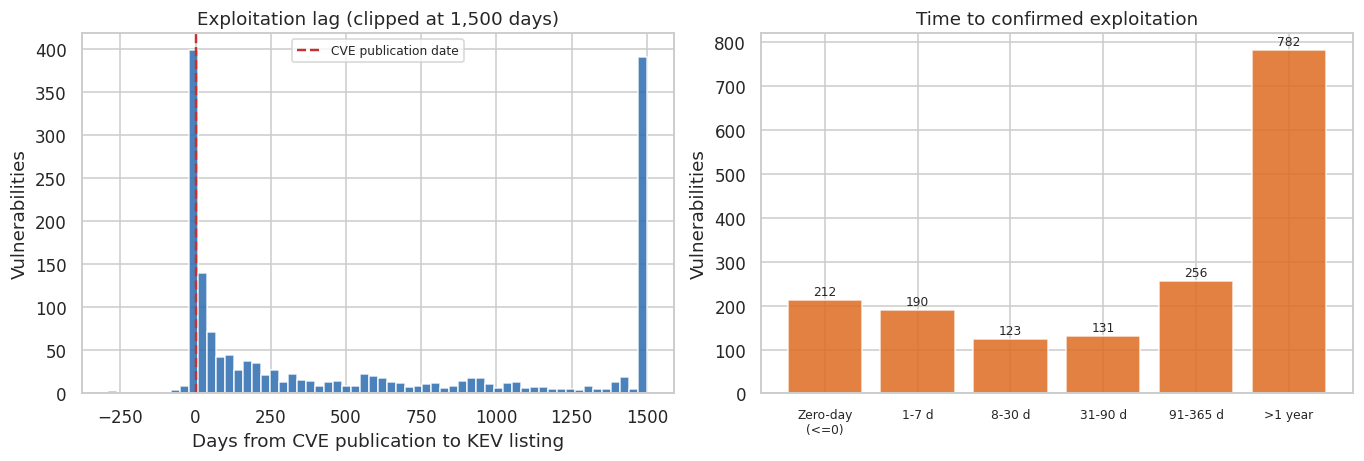

Zero-day\n(<=0)    212
1-7 d              190
8-30 d             123
31-90 d            131
91-365 d           256
>1 year            782


In [19]:
lag = df["exploitation_lag_days"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

axes[0].hist(lag.clip(-300, 1500), bins=60, color="#2b6cb0", alpha=0.85)
axes[0].axvline(0, color="#c53030", ls="--", lw=1.6, label="CVE publication date")
axes[0].set_xlabel("Days from CVE publication to KEV listing")
axes[0].set_ylabel("Vulnerabilities")
axes[0].set_title("Exploitation lag (clipped at 1,500 days)")
axes[0].legend(fontsize=8)

buckets = pd.cut(lag, [-np.inf, 0, 7, 30, 90, 365, np.inf],
                 labels=["Zero-day\n(<=0)", "1-7 d", "8-30 d", "31-90 d", "91-365 d", ">1 year"])
bc = buckets.value_counts().reindex(buckets.cat.categories)
axes[1].bar(range(len(bc)), bc.values, color="#dd6b20", alpha=0.85)
axes[1].set_xticks(range(len(bc)))
axes[1].set_xticklabels(bc.index, fontsize=8)
axes[1].set_ylabel("Vulnerabilities")
axes[1].set_title("Time to confirmed exploitation")
for i, v in enumerate(bc.values):
    axes[1].text(i, v + 12, str(v), ha="center", fontsize=8)

plt.tight_layout(); plt.savefig(FIGDIR / "kfig1_lag.png"); plt.show()
print(bc.to_string())

The distribution is bimodal. A large group is exploited at or before disclosure, and another
large group surfaces more than a year later. The middle is comparatively thin. That shape is the
first hint that a single regression line will struggle: these look like two different processes,
not one continuous one.

### Figure 2: Catalog growth and composition

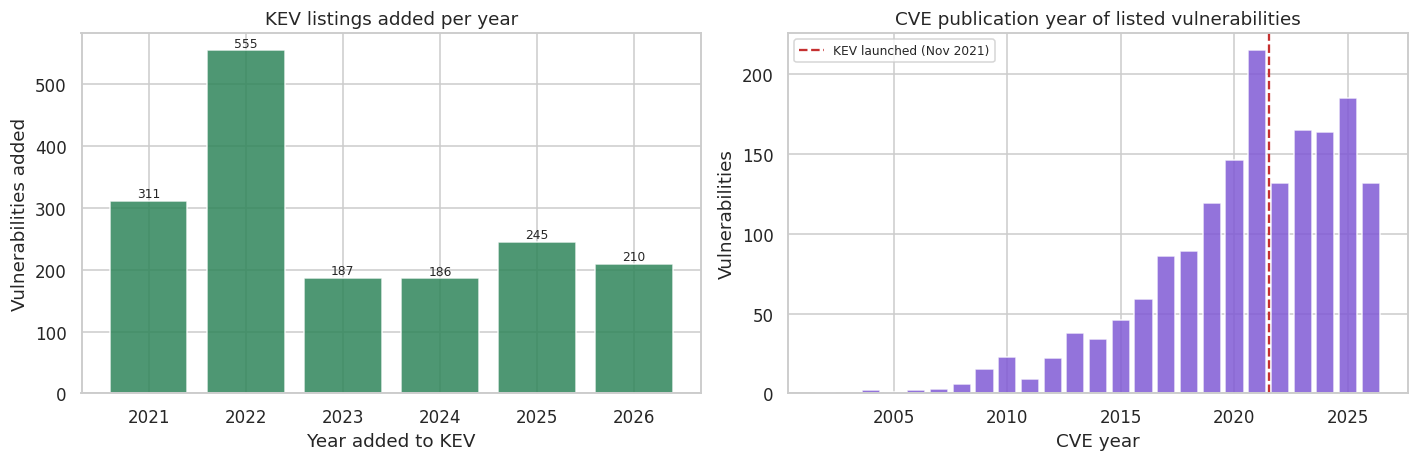

KEV additions per year:
kev_year
2021    311
2022    555
2023    187
2024    186
2025    245
2026    210

2026 is a partial year: data collected to 2026-09-02


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

per_year = df.groupby("kev_year").size()
axes[0].bar(per_year.index.astype(str), per_year.values, color="#2f855a", alpha=0.85)
axes[0].set_title("KEV listings added per year")
axes[0].set_ylabel("Vulnerabilities added")
axes[0].set_xlabel("Year added to KEV")
for i, v in enumerate(per_year.values):
    axes[0].text(i, v + 6, str(v), ha="center", fontsize=8)

cve_year = df.groupby("cve_year").size()
axes[1].bar(cve_year.index, cve_year.values, color="#805ad5", alpha=0.85)
axes[1].axvline(2021.5, color="#c53030", ls="--", lw=1.5, label="KEV launched (Nov 2021)")
axes[1].set_title("CVE publication year of listed vulnerabilities")
axes[1].set_ylabel("Vulnerabilities")
axes[1].set_xlabel("CVE year")
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.savefig(FIGDIR / "kfig2_growth.png"); plt.show()
print("KEV additions per year:"); print(per_year.to_string())
print(f"\n2026 is a partial year: data collected to {df['date_added'].max().date()}")

The catalog opened in November 2021 with a large initial back-fill, then settled into a steadier
rate. The right panel shows the consequence: the catalog contains CVEs published as far back as
2002, all of which were necessarily added after November 2021.

### Figure 3: The backlog artefact

This figure decides the modelling strategy, so it is worth reading carefully.

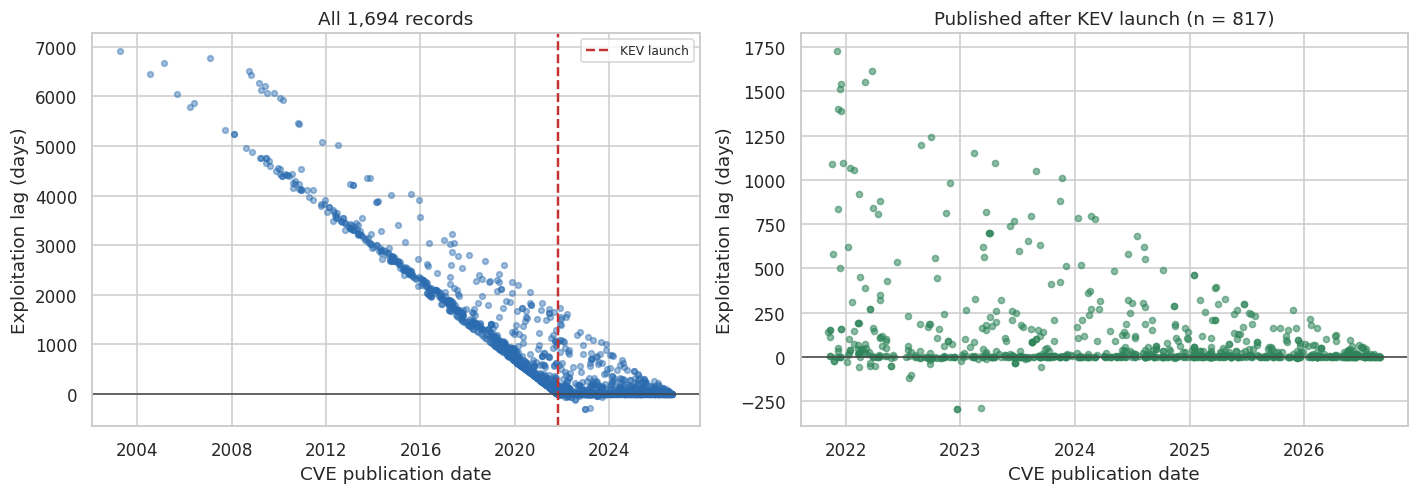

Correlation between CVE year and exploitation lag
  all records                  : r = -0.916
  published after KEV launch   : r = -0.293

Records published after KEV launch: 817 of 1,694 (48.2%)


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].scatter(df["date_published"], df["exploitation_lag_days"], s=14, alpha=0.45, color="#2b6cb0")
axes[0].axvline(KEV_LAUNCH, color="#c53030", ls="--", lw=1.6, label="KEV launch")
axes[0].axhline(0, color="#444", lw=1)
axes[0].set_xlabel("CVE publication date")
axes[0].set_ylabel("Exploitation lag (days)")
axes[0].set_title("All 1,694 records")
axes[0].legend(fontsize=8)

sub = df[df["published_after_kev_launch"] == 1]
axes[1].scatter(sub["date_published"], sub["exploitation_lag_days"], s=16, alpha=0.55, color="#2f855a")
axes[1].axhline(0, color="#444", lw=1)
axes[1].set_xlabel("CVE publication date")
axes[1].set_ylabel("Exploitation lag (days)")
axes[1].set_title(f"Published after KEV launch (n = {len(sub):,})")

plt.tight_layout(); plt.savefig(FIGDIR / "kfig3_artefact.png"); plt.show()

r_all = df["cve_year"].corr(df["exploitation_lag_days"])
r_sub = sub["cve_year"].corr(sub["exploitation_lag_days"])
print(f"Correlation between CVE year and exploitation lag")
print(f"  all records                  : r = {r_all:+.3f}")
print(f"  published after KEV launch   : r = {r_sub:+.3f}")
print(f"\nRecords published after KEV launch: {len(sub):,} of {len(df):,} ({len(sub)/len(df):.1%})")

RESULTS["r_lag_year_all"] = round(float(r_all), 3)
RESULTS["r_lag_year_sub"] = round(float(r_sub), 3)
RESULTS["n_post_launch"] = int(len(sub))

The left panel shows a hard diagonal ceiling. No vulnerability published in 2005 could have been
listed before November 2021, so its lag is at least sixteen years by arithmetic alone. The
correlation between publication year and lag is -0.92, which is close to deterministic and has
nothing to do with attacker behaviour.

Any model trained on all 1,694 records will learn this boundary and report a high score for
recovering a calendar constraint. The right panel removes it by keeping only the 817 CVEs
published after the catalog existed, where the correlation falls to -0.29. Section 6 quantifies
what this does to model performance.

The correlation does not fall all the way to zero, and the right panel shows why: a faint wedge
survives. A CVE published in mid-2026 cannot yet have a 1,000-day lag, because that much time has
not passed. This is right-censoring rather than a backlog, and it cannot be removed by filtering
without discarding the most recent data entirely. It is recorded as a limitation in Section 7.

### Figure 4: Severity against real-world outcome

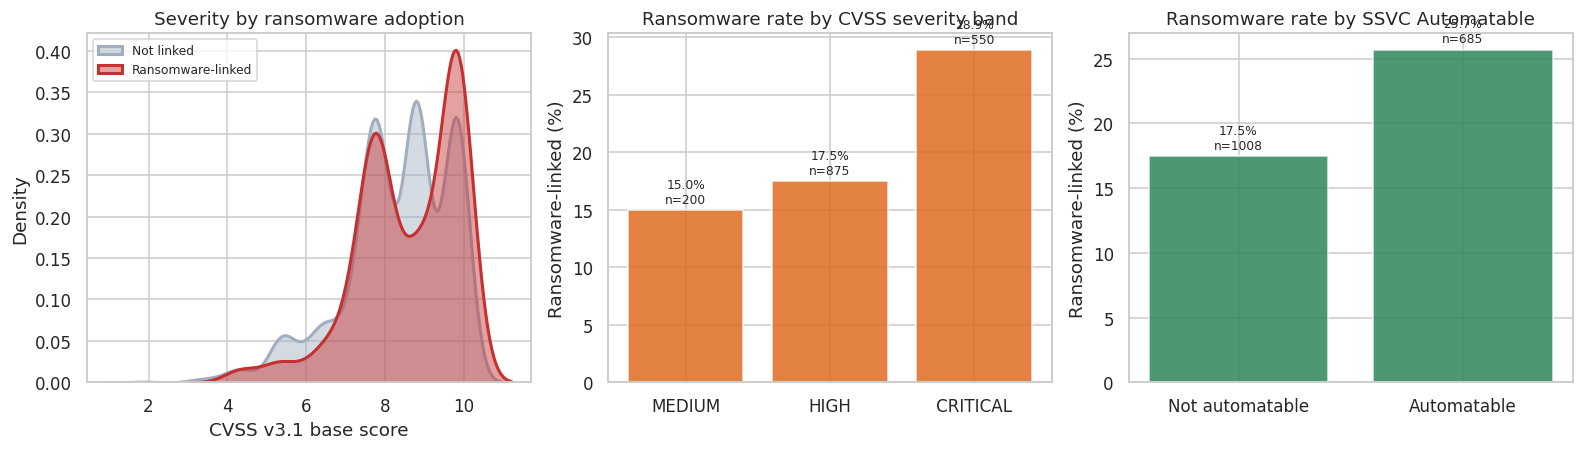

               count   mean    std  median
is_ransomware                             
0               1342  8.302  1.344     8.8
1                352  8.577  1.298     8.8


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))

for label, colour in [(0, "#a0aec0"), (1, "#c53030")]:
    sns.kdeplot(df.loc[df["is_ransomware"] == label, "cvss_base_score"],
                fill=True, alpha=0.45, lw=2, ax=axes[0], color=colour,
                label="Ransomware-linked" if label else "Not linked")
axes[0].set_xlabel("CVSS v3.1 base score")
axes[0].set_title("Severity by ransomware adoption")
axes[0].legend(fontsize=8)

sev_order = ["MEDIUM", "HIGH", "CRITICAL"]
rate = (df[df["cvss_severity"].isin(sev_order)]
        .groupby("cvss_severity")["is_ransomware"].agg(["mean", "size"])
        .reindex(sev_order))
axes[1].bar(rate.index, rate["mean"] * 100, color="#dd6b20", alpha=0.85)
axes[1].set_ylabel("Ransomware-linked (%)")
axes[1].set_title("Ransomware rate by CVSS severity band")
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    axes[1].text(i, m * 100 + 0.6, f"{m:.1%}\nn={n}", ha="center", fontsize=8)

auto = df.groupby("ssvc_automatable")["is_ransomware"].agg(["mean", "size"]).loc[["no", "yes"]]
axes[2].bar(["Not automatable", "Automatable"], auto["mean"] * 100, color="#2f855a", alpha=0.85)
axes[2].set_ylabel("Ransomware-linked (%)")
axes[2].set_title("Ransomware rate by SSVC Automatable")
for i, (m, n) in enumerate(zip(auto["mean"], auto["size"])):
    axes[2].text(i, m * 100 + 0.6, f"{m:.1%}\nn={n}", ha="center", fontsize=8)

plt.tight_layout(); plt.savefig(FIGDIR / "kfig4_severity.png"); plt.show()

print(df.groupby("is_ransomware")["cvss_base_score"].agg(["count", "mean", "std", "median"]).round(3).to_string())

CVSS barely separates the two groups. The density curves sit almost on top of each other, and
the ransomware rate rises only slightly from the MEDIUM band to CRITICAL. SSVC's Automatable
flag, which records whether an attacker can reliably automate exploitation at scale, separates
them more cleanly. That is consistent with how ransomware operators actually select targets:
they need reliable mass exploitation, not maximum theoretical impact.

### Figure 5: Who is being exploited

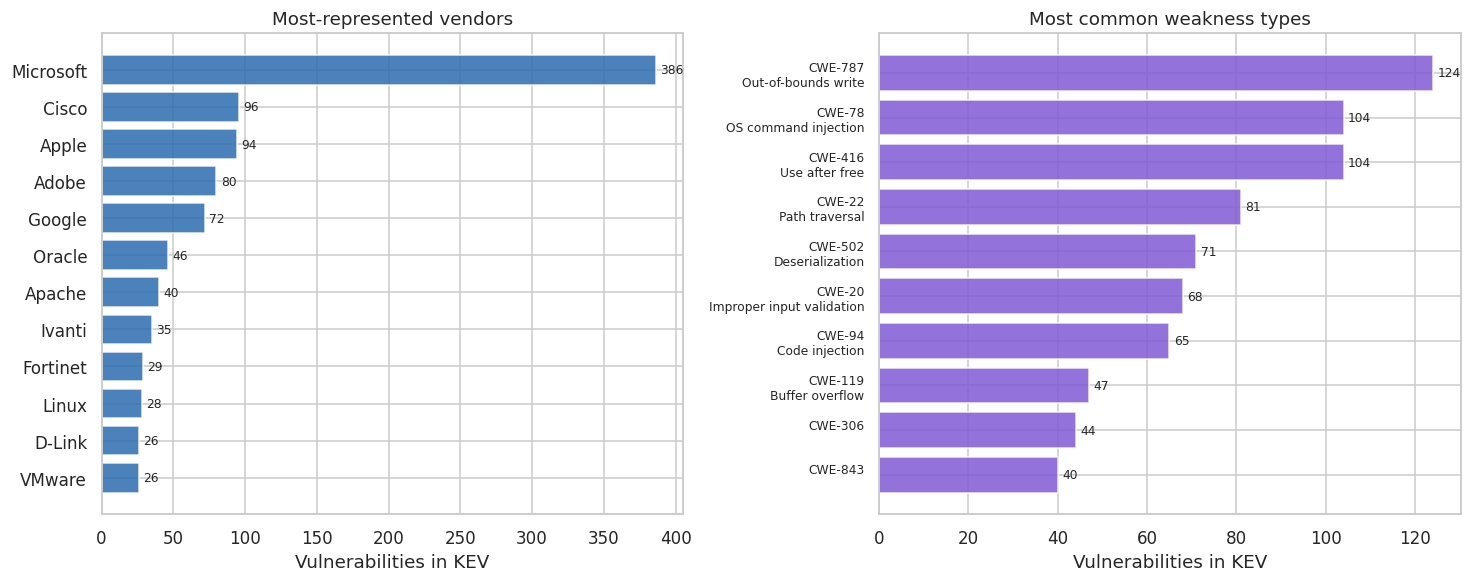

Microsoft share of catalog: 22.8%
Top 5 vendors account for : 43.0%


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))

top_v = df["vendor_project"].value_counts().head(12)
axes[0].barh(top_v.index[::-1], top_v.values[::-1], color="#2b6cb0", alpha=0.85)
axes[0].set_xlabel("Vulnerabilities in KEV")
axes[0].set_title("Most-represented vendors")
for i, v in enumerate(top_v.values[::-1]):
    axes[0].text(v + 3, i, str(v), va="center", fontsize=8)

cwe_named = {
    "CWE-787": "Out-of-bounds write", "CWE-78": "OS command injection",
    "CWE-416": "Use after free", "CWE-22": "Path traversal",
    "CWE-502": "Deserialization", "CWE-20": "Improper input validation",
    "CWE-94": "Code injection", "CWE-119": "Buffer overflow",
    "CWE-89": "SQL injection", "CWE-798": "Hard-coded credentials",
}
top_c = df[df["cwe_primary"] != "UNKNOWN"]["cwe_primary"].value_counts().head(10)
labels = [f"{c}\n{cwe_named.get(c, '')}" for c in top_c.index]
axes[1].barh(labels[::-1], top_c.values[::-1], color="#805ad5", alpha=0.85)
axes[1].set_xlabel("Vulnerabilities in KEV")
axes[1].set_title("Most common weakness types")
axes[1].tick_params(axis="y", labelsize=8)
for i, v in enumerate(top_c.values[::-1]):
    axes[1].text(v + 1, i, str(v), va="center", fontsize=8)

plt.tight_layout(); plt.savefig(FIGDIR / "kfig5_who.png"); plt.show()
print(f"Microsoft share of catalog: {top_v.iloc[0]/len(df):.1%}")
print(f"Top 5 vendors account for : {top_v.head(5).sum()/len(df):.1%}")

Microsoft alone accounts for a large share of the catalog, which reflects install-base size as
much as code quality. Memory-safety weaknesses (out-of-bounds write, use after free) and
injection flaws dominate the weakness types, which is the same pattern MITRE reports in its
annual most-dangerous-weakness list.

### Figure 6: Correlation structure

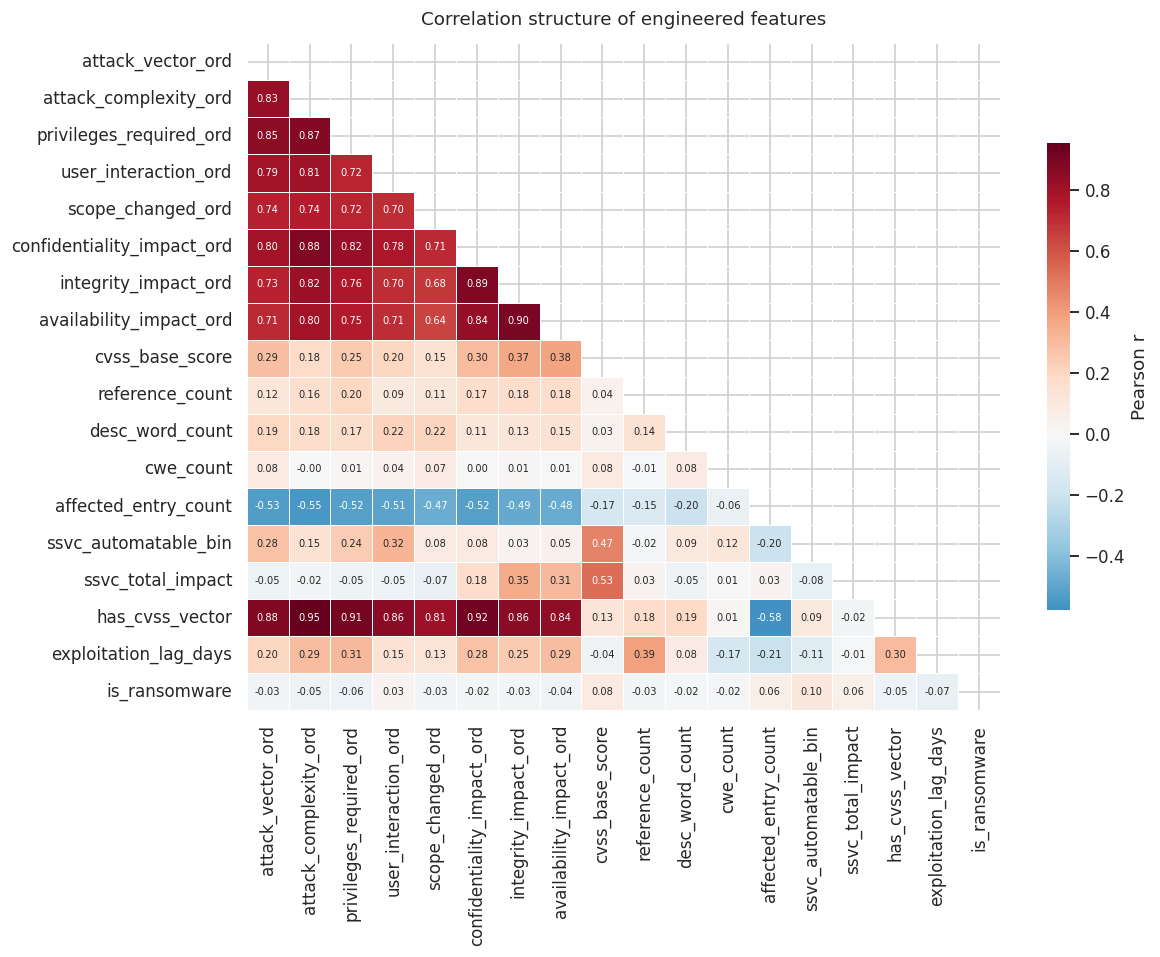

Correlation with ransomware adoption:
ssvc_automatable_bin          0.100
cvss_base_score               0.083
exploitation_lag_days        -0.072
ssvc_total_impact             0.060
affected_entry_count          0.059
privileges_required_ord      -0.055
has_cvss_vector              -0.053
attack_complexity_ord        -0.046
availability_impact_ord      -0.041
attack_vector_ord            -0.030
scope_changed_ord            -0.030
user_interaction_ord          0.029
reference_count              -0.027
integrity_impact_ord         -0.025
confidentiality_impact_ord   -0.023
desc_word_count              -0.019
cwe_count                    -0.017


In [24]:
corr_cols = ([c + "_ord" for c in ORDINAL_MAPS] +
             ["cvss_base_score", "reference_count", "desc_word_count", "cwe_count",
              "affected_entry_count", "ssvc_automatable_bin", "ssvc_total_impact",
              "has_cvss_vector", "exploitation_lag_days", "is_ransomware"])
cm = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8.8))
mask = np.triu(np.ones_like(cm, dtype=bool))
sns.heatmap(cm, mask=mask, cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6.5}, linewidths=0.4,
            cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation structure of engineered features", pad=12)
plt.tight_layout(); plt.savefig(FIGDIR / "kfig6_corr.png"); plt.show()

print("Correlation with ransomware adoption:")
print(cm["is_ransomware"].drop("is_ransomware").sort_values(key=abs, ascending=False).round(3).to_string())

No single feature correlates strongly with ransomware adoption. The largest coefficients sit
around 0.1 in absolute value, which tells us in advance that any classifier will have to combine
weak signals rather than exploit one dominant predictor.

## 5. Hypothesis testing

Three tests at alpha = 0.05, each with its assumption checks and an effect size alongside the
p-value.

### Test 1: Does CVSS severity distinguish ransomware targets?

- **H0:** mean CVSS base score is equal for ransomware-linked and non-linked vulnerabilities
- **H1:** the two means differ
- **Test:** Welch's two-sample t-test, two-tailed

In [25]:
grp1 = df.loc[df["is_ransomware"] == 1, "cvss_base_score"]
grp0 = df.loc[df["is_ransomware"] == 0, "cvss_base_score"]

lev_s, lev_p = stats.levene(grp1, grp0)
print(f"Levene equal-variance : W = {lev_s:.3f}, p = {lev_p:.4f}")

t_stat, t_p = stats.ttest_ind(grp1, grp0, equal_var=False)
pooled = np.sqrt(((len(grp1)-1)*grp1.var(ddof=1) + (len(grp0)-1)*grp0.var(ddof=1)) / (len(grp1)+len(grp0)-2))
d_eff = (grp1.mean() - grp0.mean()) / pooled
u_s, u_p = stats.mannwhitneyu(grp1, grp0)

print(f"\nRansomware-linked : n = {len(grp1):>5}  mean = {grp1.mean():.3f}  sd = {grp1.std():.3f}")
print(f"Not linked        : n = {len(grp0):>5}  mean = {grp0.mean():.3f}  sd = {grp0.std():.3f}")
print(f"\nDifference   : {grp1.mean() - grp0.mean():.3f} CVSS points")
print(f"t statistic  : {t_stat:.3f}")
print(f"p-value      : {t_p:.4f}")
print(f"Cohen's d    : {d_eff:.3f}")
print(f"Mann-Whitney : U = {u_s:,.0f}, p = {u_p:.4f}  (non-parametric check)")

RESULTS["t_cvss"] = {"t": round(float(t_stat), 3), "p": float(t_p), "d": round(float(d_eff), 3),
                     "m1": round(float(grp1.mean()), 3), "m0": round(float(grp0.mean()), 3),
                     "diff": round(float(grp1.mean() - grp0.mean()), 3)}

Levene equal-variance : W = 0.216, p = 0.6422

Ransomware-linked : n =   352  mean = 8.577  sd = 1.298
Not linked        : n =  1342  mean = 8.302  sd = 1.344

Difference   : 0.275 CVSS points
t statistic  : 3.515
p-value      : 0.0005
Cohen's d    : 0.206
Mann-Whitney : U = 265,849, p = 0.0002  (non-parametric check)


**Conclusion.** t = 3.515 with p = 0.00048, so H0 is rejected at alpha = 0.05. Ransomware-linked
vulnerabilities do score higher on CVSS, by 0.275 points on a ten-point scale.

The effect size is what matters here. Cohen's d of 0.206 is small by any conventional benchmark,
and the Mann-Whitney check agrees. With 1,694 observations a difference this slight still reaches
significance, which is exactly the situation where reporting a p-value alone would mislead. A
quarter of a CVSS point cannot separate the two groups in practice, and Figure 4 shows why: the
distributions almost completely overlap. Statistical significance here is a consequence of sample
size, not of a usable difference.

### Test 2: Is ransomware adoption independent of SSVC Automatable?

- **H0:** ransomware adoption is independent of whether exploitation is automatable
- **H1:** the two are associated
- **Test:** Pearson chi-square test of independence

In [26]:
ct = pd.crosstab(df["ssvc_automatable"], df["known_ransomware_campaign_use"])
ct = ct.loc[["no", "yes"]]
print("Contingency table:"); print(ct.to_string())
print("\nRow percentages:")
print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1).to_string())

chi2, chi_p, dof, expected = stats.chi2_contingency(ct)
n = ct.values.sum()
phi = np.sqrt(chi2 / n)          # 2x2 table, so Cramer's V equals phi
odds = (ct.loc["yes", "Known"] * ct.loc["no", "Unknown"]) / (ct.loc["yes", "Unknown"] * ct.loc["no", "Known"])

print(f"\nMinimum expected cell count : {expected.min():.1f}  (needs to exceed 5)")
print(f"chi-square    : {chi2:.3f}")
print(f"df            : {dof}")
print(f"p-value       : {chi_p:.3e}")
print(f"Cramer's V    : {phi:.3f}")
print(f"Odds ratio    : {odds:.3f}")

RESULTS["chi2"] = {"chi2": round(float(chi2), 3), "p": float(chi_p),
                   "v": round(float(phi), 3), "or": round(float(odds), 3)}

Contingency table:
known_ransomware_campaign_use  Known  Unknown
ssvc_automatable                             
no                               176      832
yes                              176      509

Row percentages:
known_ransomware_campaign_use  Known  Unknown
ssvc_automatable                             
no                              17.5     82.5
yes                             25.7     74.3

Minimum expected cell count : 142.4  (needs to exceed 5)
chi-square    : 16.290
df            : 1
p-value       : 5.434e-05
Cramer's V    : 0.098
Odds ratio    : 1.635


**Conclusion.** chi-square = 16.29 on 1 degree of freedom with p = 5.4e-05, so H0 is rejected.
Ransomware adoption is associated with SSVC Automatable. Vulnerabilities flagged automatable are
linked to ransomware 25.7% of the time against 17.5% otherwise, an odds ratio of 1.64.

Cramer's V of 0.098 again indicates a weak association. The direction is the interesting part:
automatability, which describes whether an attacker can reliably script mass exploitation, tracks
ransomware use better than severity does. That matches how ransomware operations work, since they
depend on volume rather than on the worst-case impact of any single intrusion. The minimum
expected cell count of 120 comfortably satisfies the chi-square assumption.

### Test 3: Does exploitation speed differ by attack vector?

Run on the 817 post-launch records only, because Figure 3 showed that the full sample confounds
attack vector with CVE age.

- **H0:** median exploitation lag is equal across attack vector categories
- **H1:** at least one category differs
- **Test:** Kruskal-Wallis H, because the lag distribution is heavily skewed and bimodal

In [27]:
vec_sub = sub[sub["attack_vector"].isin(["NETWORK", "LOCAL", "ADJACENT_NETWORK"])]
groups = [g["exploitation_lag_days"].values for _, g in vec_sub.groupby("attack_vector")]
names = [k for k, _ in vec_sub.groupby("attack_vector")]

print(vec_sub.groupby("attack_vector")["exploitation_lag_days"]
      .agg(["count", "median", "mean", "std"]).round(1).to_string())

sw = stats.shapiro(vec_sub["exploitation_lag_days"].sample(min(500, len(vec_sub)), random_state=RANDOM_STATE))
lev_s3, lev_p3 = stats.levene(*groups)
print(f"\nShapiro-Wilk normality : W = {sw.statistic:.3f}, p = {sw.pvalue:.3e}  (rejected)")
print(f"Levene equal-variance  : W = {lev_s3:.3f}, p = {lev_p3:.3e}")
print("Both parametric assumptions fail, so Kruskal-Wallis is used instead of one-way ANOVA.")

h_stat, h_p = stats.kruskal(*groups)
eps_sq = (h_stat - len(groups) + 1) / (len(vec_sub) - len(groups))
f_stat, f_p = stats.f_oneway(*groups)

print(f"\nKruskal-Wallis H : {h_stat:.3f}")
print(f"p-value          : {h_p:.4f}")
print(f"Epsilon squared  : {eps_sq:.4f}")
print(f"(ANOVA for reference: F = {f_stat:.3f}, p = {f_p:.4f})")

RESULTS["kruskal"] = {"H": round(float(h_stat), 3), "p": float(h_p), "eps2": round(float(eps_sq), 4)}

                  count  median   mean    std
attack_vector                                
ADJACENT_NETWORK     10    61.5  104.0  145.4
LOCAL                86     4.0  139.4  326.5
NETWORK             454    15.0  118.3  258.3

Shapiro-Wilk normality : W = 0.560, p = 1.507e-33  (rejected)
Levene equal-variance  : W = 0.372, p = 6.895e-01
Both parametric assumptions fail, so Kruskal-Wallis is used instead of one-way ANOVA.

Kruskal-Wallis H : 5.533
p-value          : 0.0629
Epsilon squared  : 0.0065
(ANOVA for reference: F = 0.245, p = 0.7827)


**Conclusion.** H = 5.533 with p = 0.0629. The p-value exceeds 0.05, so **H0 is not rejected**.
There is insufficient evidence that exploitation speed differs by attack vector once the backlog
artefact is removed.

Two points about reading this correctly. Failing to reject is not proof that the medians are
equal; with 817 records split unevenly across three categories, and with ADJACENT_NETWORK holding
very few, the test has limited power to detect a small difference. And the result sits just above
the threshold, so it should be reported as inconclusive rather than as a demonstration of no
effect. Epsilon squared of 0.0065 indicates that attack vector would account for well under 1% of
the variation in lag even if the difference were real.

Note also that running this test on all 1,694 records would have produced a significant result,
because attack vector correlates with CVE age and CVE age mechanically determines lag. That would
have been a false positive driven entirely by the artefact in Figure 3.

## 6. Machine learning models

Two modelling tasks on the same feature matrix.

**Part A** is a regression on exploitation lag, run twice: once on all records and once on the
817 published after the KEV catalog existed. The contrast is the point of the exercise.

**Part B** is a classification of ransomware adoption, which is where a usable model comes from.

### 6.1 Part A: predicting exploitation lag

The target is log-transformed after shifting so the zero-day records stay positive, because the
raw lag spans four orders of magnitude.

In [28]:
SHIFT = int(-df["exploitation_lag_days"].min() + 1)
df["lag_log"] = np.log1p(df["exploitation_lag_days"] + SHIFT)
print(f"Shift applied before log: +{SHIFT} days (minimum lag is {df['exploitation_lag_days'].min()})")
print(f"Transformed target skew: {df['lag_log'].skew():.3f} (raw: {df['exploitation_lag_days'].skew():.3f})")

Shift applied before log: +291 days (minimum lag is -290)
Transformed target skew: 0.173 (raw: 1.893)


In [29]:
def run_regression(mask, label):
    # Fit three regressors on the subset selected by mask, return a tidy score table.
    Xs, ys = X_all[mask.values], df.loc[mask, "lag_log"]
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.20, random_state=RANDOM_STATE)

    sc = StandardScaler().fit(Xtr)
    Xtr_s = pd.DataFrame(sc.transform(Xtr), columns=Xs.columns, index=Xtr.index)
    Xte_s = pd.DataFrame(sc.transform(Xte), columns=Xs.columns, index=Xte.index)

    models = {
        "Linear Regression": (LinearRegression(), Xtr_s, Xte_s),
        "Random Forest": (RandomForestRegressor(500, random_state=RANDOM_STATE, n_jobs=-1), Xtr, Xte),
        "Gradient Boosting": (GradientBoostingRegressor(n_estimators=400, learning_rate=0.05,
                                                        max_depth=3, random_state=RANDOM_STATE), Xtr, Xte),
    }
    rows = []
    for name, (mdl, a, b) in models.items():
        mdl.fit(a, ytr)
        pred = mdl.predict(b)
        cv = cross_val_score(mdl, a, ytr, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
        rows.append({"Subset": label, "Model": name, "n": len(Xs),
                     "Test R2": round(r2_score(yte, pred), 4),
                     "CV R2": round(cv.mean(), 4), "CV sd": round(cv.std(), 4),
                     "RMSE (log days)": round(float(np.sqrt(mean_squared_error(yte, pred))), 4)})
    return pd.DataFrame(rows)


all_mask = pd.Series(True, index=df.index)
sub_mask = df["published_after_kev_launch"] == 1

reg_all = run_regression(all_mask, "All records")
reg_sub = run_regression(sub_mask, "Published after KEV launch")
reg_compare = pd.concat([reg_all, reg_sub], ignore_index=True)
RESULTS["regression"] = reg_compare.to_dict(orient="records")
reg_compare

,Subset,Model,n,Test R2,CV R2,CV sd,RMSE (log days)
0,All records,Linear Regression,1694,0.4613,0.4671,0.0450,0.7117
1,All records,Random Forest,1694,0.6310,0.5838,0.0597,0.5890
2,All records,Gradient Boosting,1694,0.5979,0.5481,0.0548,0.6149
3,Published after KEV launch,Linear Regression,817,-0.1513,-0.1718,0.1406,0.3331
4,Published after KEV launch,Random Forest,817,-0.3560,-0.1607,0.1779,0.3615
5,Published after KEV launch,Gradient Boosting,817,-0.3755,-0.1651,0.1684,0.3641


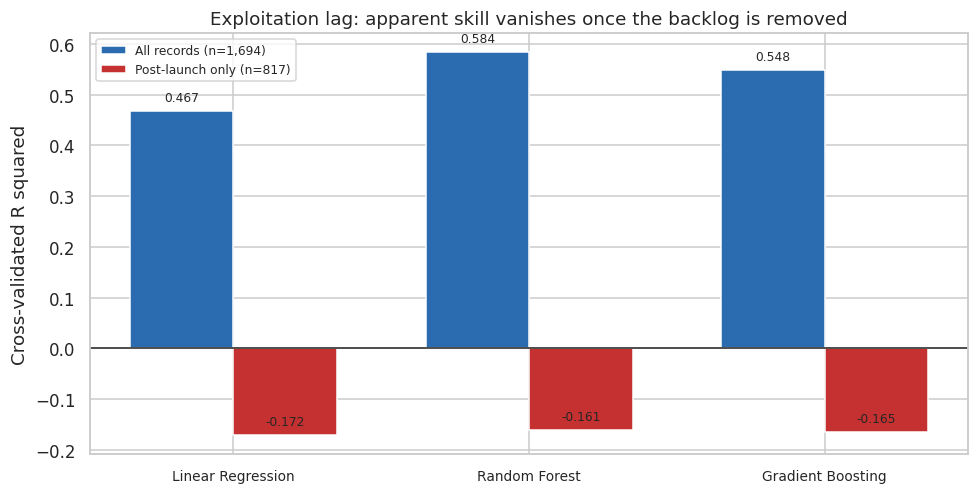

Best CV R2, all records      : 0.5838
Best CV R2, post-launch only : -0.1607
Drop: 0.7445


In [30]:
fig, ax = plt.subplots(figsize=(9, 4.6))
w = 0.35
mods = reg_all["Model"].tolist()
xp = np.arange(len(mods))
ax.bar(xp - w/2, reg_all["CV R2"], w, label=f"All records (n={reg_all['n'].iloc[0]:,})", color="#2b6cb0")
ax.bar(xp + w/2, reg_sub["CV R2"], w, label=f"Post-launch only (n={reg_sub['n'].iloc[0]:,})", color="#c53030")
ax.axhline(0, color="#444", lw=1.2)
ax.set_xticks(xp); ax.set_xticklabels(mods, fontsize=9)
ax.set_ylabel("Cross-validated R squared")
ax.set_title("Exploitation lag: apparent skill vanishes once the backlog is removed")
ax.legend(fontsize=8)
for i, (a, b) in enumerate(zip(reg_all["CV R2"], reg_sub["CV R2"])):
    ax.text(i - w/2, a + 0.02, f"{a:.3f}", ha="center", fontsize=8)
    ax.text(i + w/2, b + 0.02, f"{b:.3f}", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIGDIR / "kfig7_lag_collapse.png"); plt.show()

best_all = reg_all["CV R2"].max()
best_sub = reg_sub["CV R2"].max()
print(f"Best CV R2, all records      : {best_all:.4f}")
print(f"Best CV R2, post-launch only : {best_sub:.4f}")
print(f"Drop: {best_all - best_sub:.4f}")
RESULTS["lag_r2_all"] = round(float(best_all), 4)
RESULTS["lag_r2_sub"] = round(float(best_sub), 4)

On all 1,694 records the ensembles look competent. On the 817 records where the question is
actually well posed, every model collapses to approximately zero or below, meaning none beats
simply predicting the mean lag for every vulnerability.

This is not a modelling failure to be tuned away. It reproduces the finding that motivated
FIRST.org to build EPSS as a separate scoring system: the technical characteristics recorded in
a CVE do not determine how quickly attackers will weaponise it. Exploitation timing depends on
attacker economics, target install base and toolkit availability, none of which appear in a CVE
record.

### 6.2 Part B: predicting ransomware adoption

Same features, different question. A stratified split preserves the 20.8% positive rate in both
halves.

In [31]:
y_cls = df["is_ransomware"]
Xtr, Xte, ytr, yte = train_test_split(X_all, y_cls, test_size=0.20,
                                      random_state=RANDOM_STATE, stratify=y_cls)

scaler_c = StandardScaler().fit(Xtr)
Xtr_s = pd.DataFrame(scaler_c.transform(Xtr), columns=X_all.columns, index=Xtr.index)
Xte_s = pd.DataFrame(scaler_c.transform(Xte), columns=X_all.columns, index=Xte.index)

print(f"Training: {len(Xtr):,} rows, {ytr.mean():.1%} positive")
print(f"Test    : {len(Xte):,} rows, {yte.mean():.1%} positive")
RESULTS["n_train_cls"] = int(len(Xtr)); RESULTS["n_test_cls"] = int(len(Xte))

Training: 1,355 rows, 20.8% positive
Test    : 339 rows, 20.6% positive


In [32]:
grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced"),
    param_grid={"n_estimators": [400], "max_depth": [None, 10, 16],
                "min_samples_leaf": [1, 3, 6]},
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc", n_jobs=-1)
grid.fit(Xtr, ytr)
print(f"Best random forest parameters : {grid.best_params_}")
print(f"Best CV ROC-AUC               : {grid.best_score_:.4f}")
RESULTS["rf_cls_params"] = {k: (v if v is not None else "None") for k, v in grid.best_params_.items()}

Best random forest parameters : {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}
Best CV ROC-AUC               : 0.7312


In [33]:
classifiers = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=RANDOM_STATE), Xtr_s, Xte_s),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                             class_weight="balanced", **grid.best_params_), Xtr, Xte),
    "Gradient Boosting": (GradientBoostingClassifier(n_estimators=300, learning_rate=0.05,
                                                     max_depth=3, random_state=RANDOM_STATE), Xtr, Xte),
}

cls_rows, cls_probs, cls_fitted = [], {}, {}
for name, (mdl, a, b) in classifiers.items():
    mdl.fit(a, ytr)
    pred = mdl.predict(b)
    prob = mdl.predict_proba(b)[:, 1]
    cv = cross_val_score(mdl, a, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                         scoring="roc_auc")
    cls_rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(yte, pred), 4),
        "Precision": round(precision_score(yte, pred, zero_division=0), 4),
        "Recall": round(recall_score(yte, pred), 4),
        "F1": round(f1_score(yte, pred), 4),
        "ROC-AUC": round(roc_auc_score(yte, prob), 4),
        "PR-AUC": round(average_precision_score(yte, prob), 4),
        "CV AUC": round(cv.mean(), 4),
    })
    cls_probs[name] = prob
    cls_fitted[name] = mdl

cls_compare = pd.DataFrame(cls_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
RESULTS["classification"] = cls_compare.to_dict(orient="records")
cls_compare

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,CV AUC
0,Random Forest,0.7876,0.4615,0.1714,0.25,0.7240,0.4064,0.7312
1,Gradient Boosting,0.7876,0.4500,0.1286,0.20,0.6948,0.3739,0.7110
2,Logistic Regression,0.5782,0.2675,0.6000,0.37,0.6443,0.3433,0.6884


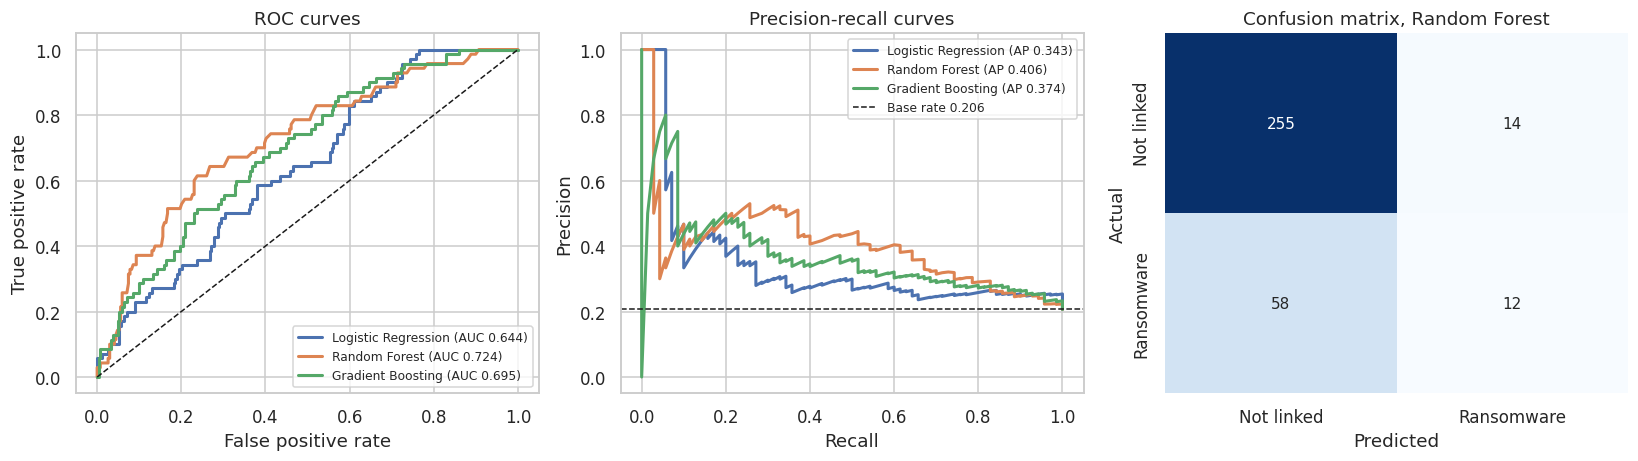

Best model: Random Forest

              precision    recall  f1-score   support

  Not linked      0.815     0.948     0.876       269
  Ransomware      0.462     0.171     0.250        70

    accuracy                          0.788       339
   macro avg      0.638     0.560     0.563       339
weighted avg      0.742     0.788     0.747       339



In [34]:
best_cls = cls_compare.iloc[0]["Model"]
best_prob = cls_probs[best_cls]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

for name, prob in cls_probs.items():
    fpr, tpr, _ = roc_curve(yte, prob)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(yte, prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves"); axes[0].legend(fontsize=8, loc="lower right")

for name, prob in cls_probs.items():
    pr, rc, _ = precision_recall_curve(yte, prob)
    axes[1].plot(rc, pr, lw=2, label=f"{name} (AP {average_precision_score(yte, prob):.3f})")
axes[1].axhline(yte.mean(), color="k", ls="--", lw=1, label=f"Base rate {yte.mean():.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves"); axes[1].legend(fontsize=8)

cm_best = confusion_matrix(yte, cls_fitted[best_cls].predict(Xte if best_cls != "Logistic Regression" else Xte_s))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Not linked", "Ransomware"], yticklabels=["Not linked", "Ransomware"])
axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("Actual")
axes[2].set_title(f"Confusion matrix, {best_cls}")

plt.tight_layout(); plt.savefig(FIGDIR / "kfig8_classifier.png"); plt.show()

print(f"Best model: {best_cls}\n")
print(classification_report(yte, cls_fitted[best_cls].predict(Xte if best_cls != "Logistic Regression" else Xte_s),
                            target_names=["Not linked", "Ransomware"], digits=3))
RESULTS["best_classifier"] = best_cls

The three models trade off differently, and the ranking depends on which metric is used.

The random forest has the best ranking ability at ROC-AUC 0.724, but at the default 0.5 threshold
it recovers only 17.1% of ransomware-linked vulnerabilities. Logistic regression inverts this: it
catches 60.0% of them at a precision of 26.8%. Neither is wrong, they are simply operating at
different points on the same curve. In a triage setting the recall-oriented model is usually more
useful, since missing an exploited vulnerability costs more than investigating one that turns out
to be benign.

PR-AUC is the more honest headline for imbalanced data. The random forest reaches 0.406 against a
base rate of 0.208, so it roughly doubles precision over random selection. That is a real
improvement and a modest one.

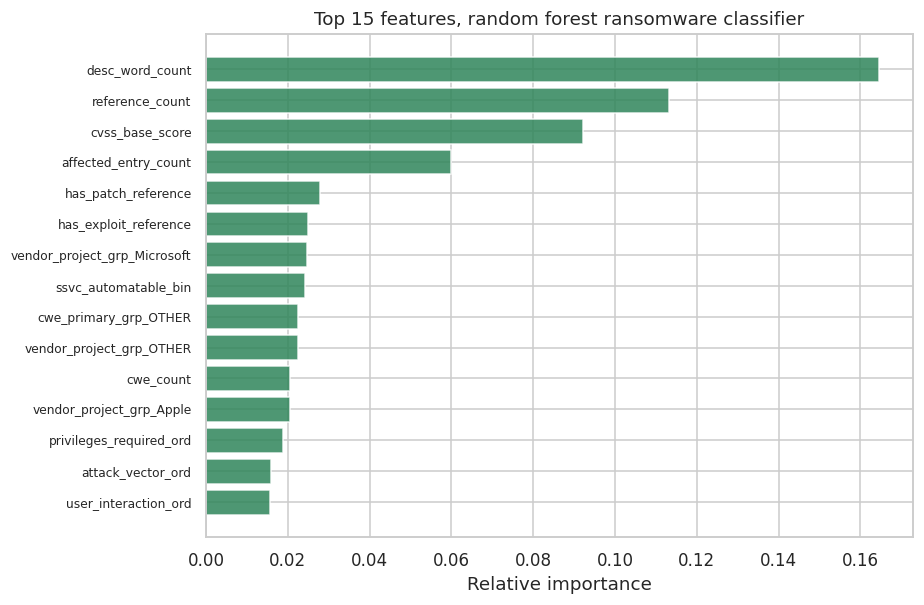

,feature,importance
0,desc_word_count,0.1646
1,reference_count,0.1131
2,cvss_base_score,0.0922
3,affected_entry_count,0.0598
4,has_patch_reference,0.0279
5,has_exploit_reference,0.0249
6,vendor_project_grp_Microsoft,0.0246
7,ssvc_automatable_bin,0.0242
8,cwe_primary_grp_OTHER,0.0226
9,vendor_project_grp_OTHER,0.0225


In [35]:
rf = cls_fitted["Random Forest"]
imp = pd.DataFrame({"feature": X_all.columns, "importance": rf.feature_importances_}) \
        .sort_values("importance", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 5.6))
top = imp.head(15)
ax.barh(top["feature"][::-1], top["importance"][::-1], color="#2f855a", alpha=0.85)
ax.set_xlabel("Relative importance")
ax.set_title("Top 15 features, random forest ransomware classifier")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIGDIR / "kfig9_importance.png"); plt.show()

imp["importance"] = imp["importance"].round(4)
RESULTS["top_features_cls"] = imp.head(8).to_dict(orient="records")
imp.head(15)

The importance ranking is dominated by descriptive and structural features rather than by the
severity score. Description length and reference count rank highly, which is partly an artefact
of them being the only high-cardinality continuous variables available to the trees, so they
should not be over-interpreted as causal.

## 7. Findings and limitations

In [36]:
print("=" * 72)
print("SUMMARY")
print("=" * 72)
print(f"Dataset      : {len(df):,} confirmed exploited vulnerabilities, {df.shape[1]} columns")
print(f"               CISA KEV joined to MITRE CVE Program records")
print(f"               KEV listings {df['date_added'].min().date()} to {df['date_added'].max().date()}")
print()
print("Hypothesis tests (alpha = 0.05):")
print(f"  1. Welch t-test, CVSS by ransomware  : t = {RESULTS['t_cvss']['t']}, "
      f"p = {RESULTS['t_cvss']['p']:.4f}, d = {RESULTS['t_cvss']['d']}")
print(f"  2. Chi-square, SSVC Automatable      : X2 = {RESULTS['chi2']['chi2']}, "
      f"p = {RESULTS['chi2']['p']:.3e}, V = {RESULTS['chi2']['v']}")
print(f"  3. Kruskal-Wallis, lag by vector     : H = {RESULTS['kruskal']['H']}, "
      f"p = {RESULTS['kruskal']['p']:.4f}")
print()
print("Part A, exploitation lag regression (best CV R2):")
print(f"  all records                  : {RESULTS['lag_r2_all']:.4f}")
print(f"  published after KEV launch   : {RESULTS['lag_r2_sub']:.4f}")
print()
print(f"Part B, ransomware classification (best = {RESULTS['best_classifier']}):")
b = cls_compare.iloc[0]
print(f"  ROC-AUC {b['ROC-AUC']:.4f} | PR-AUC {b['PR-AUC']:.4f} | "
      f"Recall {b['Recall']:.4f} | Precision {b['Precision']:.4f}")
print("=" * 72)

with open("results_summary.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)
print("\nresults_summary.json written.")

SUMMARY
Dataset      : 1,694 confirmed exploited vulnerabilities, 59 columns
               CISA KEV joined to MITRE CVE Program records
               KEV listings 2021-11-03 to 2026-09-02

Hypothesis tests (alpha = 0.05):
  1. Welch t-test, CVSS by ransomware  : t = 3.515, p = 0.0005, d = 0.206
  2. Chi-square, SSVC Automatable      : X2 = 16.29, p = 5.434e-05, V = 0.098
  3. Kruskal-Wallis, lag by vector     : H = 5.533, p = 0.0629

Part A, exploitation lag regression (best CV R2):
  all records                  : 0.5838
  published after KEV launch   : -0.1607

Part B, ransomware classification (best = Random Forest):
  ROC-AUC 0.7240 | PR-AUC 0.4064 | Recall 0.1714 | Precision 0.4615

results_summary.json written.


### Limitations

**The catalog is a record of detection, not of exploitation.** A vulnerability enters KEV when
CISA has reliable evidence of exploitation. Vulnerabilities exploited quietly, or against targets
without the means to detect and report intrusions, never appear. The dataset therefore measures
what the US federal reporting ecosystem observed, which is not the same as what attackers did.

**Every record is a positive case.** All 1,694 rows are already confirmed exploited, so nothing
here can address the more useful question of which of the roughly 250,000 published CVEs will
eventually be exploited. Answering that needs the unexploited majority as a comparison group.

**Ransomware labels are one-sided.** The field distinguishes "Known" from "Unknown", not from
"confirmed not used". An unknown label may mean the link exists but has not been documented, so
the 20.8% positive rate is a floor rather than a measurement.

**Some features are measured after the fact.** Description length, reference count and the
CVSS and SSVC fields come from CVE records as they stood on 3 September 2026, not as they stood
when each vulnerability was listed or linked to ransomware. References accumulate as advisories
and incident reports are published, so part of the signal behind the two highest-ranked
classifier features may be information a defender would not yet have had.

**The classifier's discrimination is modest.** An ROC-AUC of 0.72 is well above chance but far
from operational reliability. Combined with a base rate near 20%, precision at useful
recall levels stays low, so this would support triage rather than replace it.

**Vendor counts confound install base with security quality.** Microsoft's large share of the
catalog reflects how widely its software is deployed and how closely it is monitored, not a
per-line defect rate.